# LeetCode #53: Maximum Subarray

https://leetcode.com/problems/maximum-subarray/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force** | $O(n^2)$ | $O(1)$ | Adds up every run. About 5 billion additions at the maximum size — far too slow. |
| **Divide and conquer** | $O(n \log n)$ | $O(\log n)$ | Fast enough, but it's a page of code and the recursion costs stack depth. |
| **Running sum (Kadane's) ★** | $O(n)$ | $O(1)$ | One pass, two variables, four lines. Nothing to beat here. |

A **subarray** is a run of neighbouring elements — `[4,-1,2]` is a subarray of
`[-2,1,-3,4,-1,2,1]`, but `[4,2]` is not, because you skipped the `-1`. You must pick at least
one element.

`n` is the length of the array. $O(n)$ means **"the work grows in step with the array"** — at the
maximum size of $10^5$, about 100,000 steps. $O(n^2)$ means it grows with the *square*: there are
$n(n+1)/2$ subarrays, around $5 \times 10^9$ at $10^5$, which will not finish in time. The
$\log n$ is how many times you can halve the array before reaching single elements — about 17
here, so $O(n \log n)$ costs roughly 17× the linear version.

---

## Understanding the methods

### Brute force

Take every start position, and from each one keep extending to the right, tracking the running
total and the best total seen. Correct, no extra memory, and quadratic because it re-adds the
same prefixes over and over.

### Divide and conquer

Split the array in half. The best run either sits entirely in the left half, entirely in the
right half, or straddles the middle — and the straddling case can be measured in one linear
sweep outward from the centre. Recurse on the halves and take the best of the three. Elegant,
genuinely $O(n \log n)$, and strictly worse than the next one on every axis that matters.

### Optimal: running sum, a.k.a. Kadane's algorithm ★

Walk the array once, carrying a single number: the best total of any run that *ends at the
element you're standing on*. At each step there are only two candidates for that — extend the
previous run by adding the current element, or throw the previous run away and start fresh here.
Take the larger. Then keep a separate record of the best value that number has ever reached,
which is the answer.

The name attached to this is **Kadane's algorithm**, and it's the smallest dynamic-programming
solution there is: a DP table whose rows you never need to keep, because each row only ever
looks at the one before it.

**Why this beats divide and conquer:** same answer, one pass instead of $\log n$ levels of
recursion, constant memory instead of a call stack, and about four lines instead of forty.

**When you'd reach for each:** Kadane's, essentially always. Brute force only as the thing you
say out loud first so your interviewer knows what you're improving on. Divide and conquer earns
its keep only when the question changes — if you had to answer "best run inside this slice of
the array" repeatedly, the merge-style information it computes is what a segment tree stores.

**Constraints:**
* $1 \leq \text{nums.length} \leq 10^5$ — the array is never empty
* $-10^4 \leq \text{nums}[i] \leq 10^4$


## Explain Like I'm a Newbie

### What the question is actually asking

Find the run of neighbouring numbers with the biggest total. Neighbouring matters: you have to
take a solid block, no skipping, and you must take at least one number.

```
nums = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
                    ^^^^^^^^^^^^
                    4 + -1 + 2 + 1 = 6   <- the best you can do
```

### The one idea you need: a negative running total is never worth keeping

Trying every block works and is far too slow. The insight that replaces it is about when the
past stops being useful.

Suppose the best run ending just before you added up to `-3`. Should you extend it? No — you'd
be starting from `-3` instead of from `0`, so whatever comes next, you're strictly better off
dropping everything behind you and beginning again here. And if the total behind you is
*positive*, you always keep it: it can only help.

So at every element there are exactly two options, and no searching:

- **extend**: `running total so far + this element`
- **restart**: `this element` on its own

Take whichever is bigger, and that's the best run ending at your current position. Then
separately remember the largest value that has ever been, because the answer is allowed to end
anywhere. That's **Kadane's algorithm**.

### What that means in code

```
current = nums[0]          # best run ending at position 0
best    = nums[0]          # best run ending anywhere so far

for each num after the first:
    current = max(num, current + num)
    best    = max(best, current)

return best
```

Two things have to be right. **Both variables start at `nums[0]`, not at `0`.** Starting at
zero quietly assumes the empty run is allowed, and it isn't — on an all-negative array like
`[-3,-1,-4]` you'd return `0` instead of `-1`.

**`current` and `best` are different things.** `current` is forced to end where you are
standing, so it goes down as well as up. `best` only ever goes up. Collapse them into one
variable and you lose the answer the moment the array dips after its best run.

### Three mistakes people make the first time

1. **Initialising to `0`.** Returns `0` for every all-negative array. The single most common
   bug here, and it passes the sample input.
2. **Using one variable instead of two.** `[3, -1, -1]` returns `1` instead of `3`.
3. **Resetting `current` to `0` instead of to `num`.** Close, and wrong on an all-negative
   array for the same reason as mistake 1.

### Two things worth knowing

**No overflow risk.** The largest total possible is every element at its maximum:
$10^5 \times 10^4 = 10^9$, comfortably inside a 32-bit signed integer's $\pm 2.147 \times 10^9$.
Worth checking rather than assuming, because sum-over-array problems often do overflow.

**It finds the total, not the run.** For the start and end indices you'd record where `current`
last restarted and where `best` last improved — same single pass, two more variables.


## Talking It Through in an Interview

*Written from the interviewer's chair — what I want to hear from you, from the moment I hand the
problem over to the moment the code's on the board.*

---

### The thirty-second version

By the end you should be able to say: *"I carry one number — the best run that ends where I'm
standing — and at each element I either extend it or throw it away and start fresh, whichever is
larger. A second variable remembers the best it's ever been. One pass, two variables, and the
only thing that needs care is initialising to `nums[0]` rather than zero, because the empty run
isn't allowed."*

Ending on the thing that's easy to get wrong is better than ending on how fast it is.

---

### I slide the problem across the table

An integer array. Find the contiguous subarray with the largest sum, and return that sum.

> **You:** "So, a solid block of neighbouring elements — no skipping — and I return the total, not
> the block itself. Two things I want to pin down. Can the subarray be empty? If every number's
> negative, is the answer zero, or is it the least-bad single element?"

That's the question I'm listening for on this problem, and it's the one that separates people who
read the statement from people who recognised it. It isn't cosmetic — it changes your
initialisation and it's the bug this problem is famous for. I'll say: **"Non-empty. At least one
element, so an all-negative array returns its largest element."**

> **You:** "Good, that's what I'd have assumed but it's exactly where I'd have gone wrong. And
> second: do you want the indices as well, or just the sum?"

Also real, because it changes what you track. **"Just the sum — but tell me what would change if
I wanted the indices."**

> **You:** "Two more variables, same single pass: where `current` last restarted, and where
> `best` last improved."

What I don't want instead is the recited list. *"Can the array be null? Are the values integers?
Is it sorted?"* The length constraint already tells you it's never empty, sortedness would make
this a different and trivial problem, and none of it changes a line.

---

### Now tell me what's actually hard about it

If your first sentence is **"this is Kadane's algorithm"**, I've learned that you know its name.
What I want is the reason it works, because the whole problem is one non-obvious claim.

> **You:** "Brute force is every start paired with every end — $n(n+1)/2$ subarrays, so about
> five billion at $10^5$. Too slow, and it's slow because it re-adds the same prefixes over and
> over.
>
> So I want one pass. The hard part is that the answer's an interval, and normally you can't
> decide an interval's boundaries by looking at one element at a time. What makes it possible
> here is a question with only two answers: if I fix where the run *ends*, what's the best run
> ending there? Either it's the best run ending one position earlier, extended by this element —
> or it's this element alone."

> **You:** "And I can decide between those two locally. If the best run ending just before me
> sums to something negative, carrying it forward strictly hurts: I'd be starting from a deficit
> instead of from zero, so I drop it. If it's positive, keeping it can only help. That's the whole
> insight — a negative running total is never worth keeping."

That's the beat I'm grading, and it's the one that almost nobody says out loud. Naming Kadane's
proves recall; "a negative prefix is never worth keeping" proves you could have derived it.

---

### The shape, and the cost derived

> **You:** "Two variables and one loop. `current` is the best run ending at where I am, `best` is
> the best I've seen anywhere. Each element does two comparisons and two assignments, so that's
> constant work $n$ times — $O(n)$, and that's the floor, because the maximum could involve the
> last element and I can't know that without reading it. Space is two integers regardless of
> input size, so $O(1)$."

Then the sentence I'd push for if you didn't volunteer it:

> **You:** "The reason two variables are needed rather than one is that `current` is *forced* to
> end at my position, so it goes down as well as up. `best` is a high-water mark and only goes
> up. If I merged them, an array like `[3, -1, -1]` would return 1 instead of 3."

If you don't say that, I'll ask why you can't just return `current`. Having the counterexample
ready is a much stronger answer than reasoning it out on the spot.

---

### Now whiteboard it

```
current = nums[0]
best    = nums[0]

for num in nums[1:]:
    current = max(num, current + num)
    best    = max(best, current)

return best
```

**On the two initialisations:**

> **You:** "Both seeded from `nums[0]`, not zero — that's the decision that comes straight out of
> your answer that the subarray can't be empty. Seed them at zero and `[-3,-1,-4]` returns 0,
> which isn't a valid subarray at all. It's also why I start the loop at index 1: element 0 is
> already accounted for."

That's the sentence I'm waiting for. Skip it and I'll hand you `[-3,-1,-4]` and watch.

**On `current = max(num, current + num)`:**

> **You:** "The extend-or-restart decision. `num` on its own wins exactly when `current` is
> negative, which is the case where the past is a liability."

**On `best = max(best, current)`:**

> **You:** "Separate line, and after the update, so it sees the run ending here. This is what
> lets the answer sit in the middle of the array rather than at the end."

---

### Walk me through it before you hand back the pen

> **You:** "`[-2,1,-3,4,-1,2,1,-5,4]`. Start both at -2. At 1: `current` is max(1, -1) = 1, so it
> restarts — `best` goes to 1. At -3: max(-3, -2) = -2, extend; `best` stays 1. At 4: max(4, 2) =
> 4, restart because the prefix was negative; `best` is 4. Then -1 takes `current` to 3, 2 takes
> it to 5, 1 takes it to 6, and `best` is 6. Then -5 drops `current` to 1 but `best` holds at 6,
> which is the whole point of keeping them apart. The last 4 brings `current` to 5, still under 6.
> Answer 6, the run `4,-1,2,1`.
>
> And the case I asked about: `[-3,-1,-4]`. Both start at -3. At -1: max(-1, -4) = -1, so `best`
> improves to -1. At -4: max(-4, -5) = -4, `best` holds. Returns -1, the largest single element —
> which is right because the subarray has to be non-empty."

The second trace is the one that matters. It's three elements long, it demonstrates the exact bug
this problem produces, and it closes the loop on your first clarifier.

---

### Then tell me where it breaks, before I ask

> **You:** "Honestly, I don't think this one breaks. It's $O(n)$ time, which is the floor, and
> $O(1)$ space, which can't be improved. No recursion, so no stack depth to worry about. And no
> overflow: the biggest possible total is $10^5$ elements at $10^4$ each, which is $10^9$ — inside
> a 32-bit signed integer, though I'd want to say that out loud rather than assume it, because
> sum-over-array problems often do overflow.
>
> What I'd flag instead is scope. It gives the total, not the indices, and it assumes I get to see
> the array in order from the start. If elements could be *removed* as well as added, or you
> wanted the best run inside arbitrary slices on demand, this doesn't adapt — I'd want a segment
> tree holding the same four quantities the divide-and-conquer version computes."

"This solution has no real weakness" is the honest answer here, and I'd much rather hear it with
a scope caveat attached than watch you invent a flaw to sound thorough.

---

### What would worry me

- **Initialising to zero.** The one real bug, and it passes the sample input, so your own dry run
  on an all-negative array is what should catch it.
- **The name with no derivation.** "It's Kadane's" tells me you've seen it. I need to hear why a
  negative prefix gets dropped.
- **One variable instead of two.** If you can't say why `best` is separate, I'll assume you
  copied the shape.
- **Reaching for divide and conquer.** It works and it's $O(n \log n)$. Choosing it over four
  lines of linear code suggests you're optimising for looking clever.


## Solutions

All four read the same way: two variables seeded from the first element, then one pass making the
extend-or-restart decision. The comments mark the two places the logic turns — why the seed is
`nums[0]` and not `0`, and why the running total and the best-ever total have to stay separate.

### C#

`Math.Max` on two `int`s; nothing language-specific beyond that.

In [ ]:
public class Solution {
    // Seeded from the first element, NOT from 0. The subarray has to be non-empty, and
    // seeding at 0 silently allows the empty run: on an all-negative array like
    // [-3,-1,-4] it would return 0 instead of -1. It is also why the loop starts at 1.
    public int MaxSubArray(int[] nums) {
        int currentSum = nums[0];   // best run that ENDS at the current position
        int maxSum = nums[0];       // best run seen anywhere so far

        for (int i = 1; i < nums.Length; i++) {
            // Extend or restart, and nothing else is possible. nums[i] alone wins exactly
            // when currentSum is negative — a negative prefix is never worth carrying,
            // because it means starting from a deficit rather than from zero.
            currentSum = Math.Max(nums[i], currentSum + nums[i]);

            // Separate variable, updated after currentSum. currentSum is forced to end
            // here so it falls as well as rises; maxSum is a high-water mark. Merge the
            // two and [3,-1,-1] returns 1 instead of 3.
            maxSum = Math.Max(maxSum, currentSum);
        }

        return maxSum;
    }
}

### Python

`nums[1:]` copies the tail of the list, which costs $O(n)$ extra memory. Harmless at this
problem's size, and `for i in range(1, len(nums))` is the allocation-free version if you need
the stated $O(1)$ space to be literally true.

In [ ]:
class Solution:
    def maxSubArray(self, nums: list[int]) -> int:
        # Seeded from the first element, NOT from 0. The subarray has to be non-empty, and
        # seeding at 0 silently allows the empty run: on an all-negative array like
        # [-3,-1,-4] it would return 0 instead of -1. It is also why the loop skips nums[0].
        current_sum = nums[0]   # best run that ENDS at the current position
        max_sum = nums[0]       # best run seen anywhere so far

        for num in nums[1:]:
            # Extend or restart, and nothing else is possible. num alone wins exactly when
            # current_sum is negative — a negative prefix is never worth carrying, because
            # it means starting from a deficit rather than from zero.
            current_sum = max(num, current_sum + num)

            # Separate variable, updated after current_sum. current_sum is forced to end
            # here so it falls as well as rises; max_sum is a high-water mark. Merge the
            # two and [3,-1,-1] returns 1 instead of 3.
            max_sum = max(max_sum, current_sum)

        return max_sum

### Go

Go has no generic `max` for `int` before 1.21, so both comparisons are written out as `if`
statements. `num > currentSum+num` is the same test as `currentSum < 0`, just phrased to mirror
the other three languages.

In [ ]:
func maxSubArray(nums []int) int {
    // Seeded from the first element, NOT from 0. The subarray has to be non-empty, and
    // seeding at 0 silently allows the empty run: on an all-negative array like
    // [-3,-1,-4] it would return 0 instead of -1. It is also why the loop skips nums[0].
    currentSum := nums[0]   // best run that ENDS at the current position
    maxSum := nums[0]       // best run seen anywhere so far

    for _, num := range nums[1:] {
        // Extend or restart, and nothing else is possible. The test num > currentSum+num
        // is just currentSum < 0 rearranged: a negative prefix is never worth carrying,
        // because it means starting from a deficit rather than from zero.
        if num > currentSum+num {
            currentSum = num
        } else {
            currentSum += num
        }

        // Separate variable, updated after currentSum. currentSum is forced to end here
        // so it falls as well as rises; maxSum is a high-water mark. Merge the two and
        // [3,-1,-1] returns 1 instead of 3.
        if currentSum > maxSum {
            maxSum = currentSum
        }
    }

    return maxSum
}

### Rust

`i32::max` is a method on the value, so the comparison reads `num.max(current_sum + num)` rather
than `max(a, b)`.

In [ ]:
impl Solution {
    pub fn max_sub_array(nums: Vec<i32>) -> i32 {
        // Seeded from the first element, NOT from 0. The subarray has to be non-empty, and
        // seeding at 0 silently allows the empty run: on an all-negative array like
        // [-3,-1,-4] it would return 0 instead of -1. It is also why the loop skips nums[0].
        let mut current_sum = nums[0];   // best run that ENDS at the current position
        let mut max_sum = nums[0];       // best run seen anywhere so far

        for &num in &nums[1..] {
            // Extend or restart, and nothing else is possible. num alone wins exactly when
            // current_sum is negative — a negative prefix is never worth carrying, because
            // it means starting from a deficit rather than from zero.
            current_sum = num.max(current_sum + num);

            // Separate variable, updated after current_sum. current_sum is forced to end
            // here so it falls as well as rises; max_sum is a high-water mark. Merge the
            // two and [3,-1,-1] returns 1 instead of 3.
            max_sum = max_sum.max(current_sum);
        }

        max_sum
    }
}

## Example Scenarios

### 1. Common Case
**Input:** `nums = [-2,1,-3,4,-1,2,1,-5,4]`

The leading negatives get dropped rather than carried, because a negative running total is never
worth keeping. The run restarts at `4` and then grows through `-1, 2, 1` — the small dip is worth
absorbing because what follows outweighs it. Best total $4 - 1 + 2 + 1 = 6$.

### 2. Slightly Complex
**Input:** `nums = [-2,-3,4,-1,-2,1,5,-3]`

The winning run $4, -1, -2, 1, 5$ contains three negative numbers. They survive because the
running total never actually goes negative on the way through — it dips to 1 and recovers — so
there's never a moment where restarting would have been better. Best total $= 7$.

### 3. Edge Case: Time
**Input:** `nums = [1,2,3,-20,7,8,9,10]`

One pass regardless of length, so the cost is $O(n)$ whatever the shape. Here the first block
reaches 6 and then `-20` drives the running total to $-14$; the next element restarts from
scratch rather than inheriting that deficit, and the second block $7+8+9+10$ wins with $34$.

### 4. Edge Case: Space
**Input:** `nums = [3,-1,4,-1,5]`

Only two integers are ever held — no prefix-sum array, no DP table — which is the whole $O(1)$
space claim. Every dip here is small enough to absorb, so the best run is the entire array,
$= 10$.

### 5. Almost-Impossible but Plausible
**Input:** `nums = [-3,-1,-4,-2]`

No positive values at all, so every extension makes things worse and the best run is a single
element: $-1$. This is the case that makes the initialisation matter — seeding `best` at `0`
rather than at `nums[0]` would return `0`, which isn't the total of any non-empty subarray.


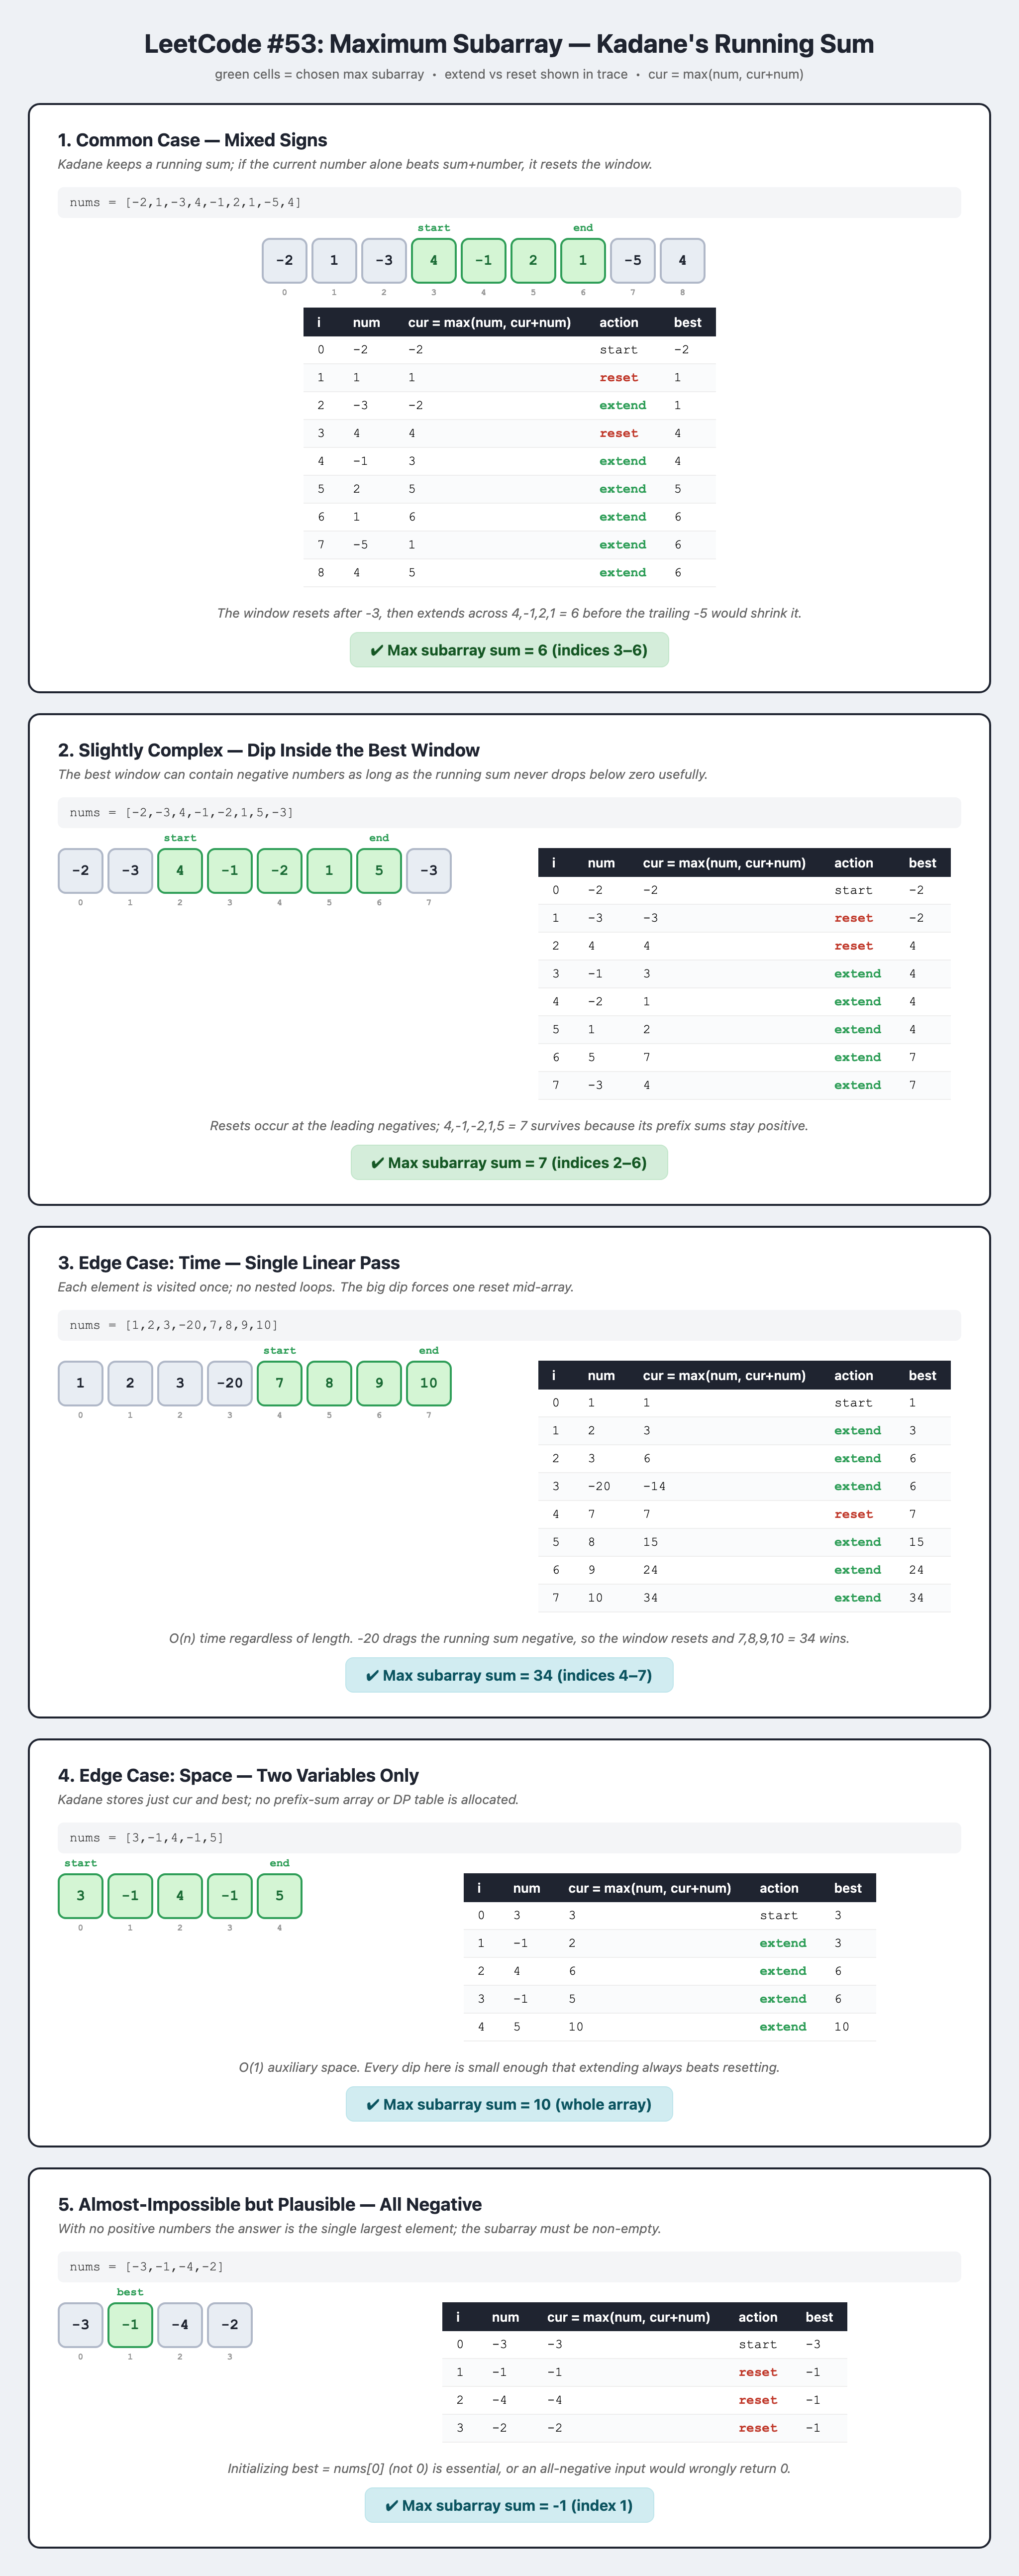